In [1]:
# =============================================================================
# Created By:     Kai Metzger
# Created School: Franz-Oberthuer-Schule Wuerzburg
# Created Email:  metzgerkai@franz-oberthuer-schule.de
# Created Date:   Sat April 05 09:54 UTC 2025
# Changed Date:   Wed November 12 09:41 UTC 2026
# Version:        1.0.2
# =============================================================================
"""Train the fully connected network with the symbols dataset.
The dataset uses one subfolder per class (0, 1, 2, 3), matching
02b symbols-dataset-training-cnn.ipynb.
"""

# =============================================================================
# Import
# =============================================================================
import cv2
import os
import numpy as np
from pathlib import Path
from keras import layers, models, callbacks
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import splitfolders

# Enable Nvidia GPUs by un-commenting this line 
os.environ['CUDA_VISIBLE_DEVICES'] = "0"
XLA_FLAGS="--xla_gpu_cuda_data_dir=/usr/"

# To get reproducable results with the same training setting random seed
SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

DEBUG = True
debug = DEBUG

In [2]:
# =============================================================================
# Declare variables / Dataset
# =============================================================================
# Change the following paths to your dataset path
home_dir = os.path.expanduser("~")
dataset = "1"                                            # CHANGE DATASET NUMBER

dataset_for_training = "dataset" + str(dataset)
dataset_for_training_split = dataset_for_training + "-split70-15-15"
checkpoint_filepath = home_dir + "/ml_project/datasets/symbols/" + "chpt/"
print(dataset_for_training)
print(checkpoint_filepath)

dataset1
/home/pi/ml_project/datasets/symbols/chpt/


In [3]:
# =============================================================================
# Split into 70% train, 15% val, 15% test on disk
# =============================================================================
split_dir = Path(dataset_for_training_split)

if not split_dir.exists():
    splitfolders.ratio(
        input=str(dataset_for_training),
        output=str(split_dir),
        shuffle=True,
        seed=SEED,
        ratio=(0.70, 0.15, 0.15),
    )
else:
    print(f"Split folder already exists; skipping: {split_dir}")

Split folder already exists; skipping: dataset1-split70-15-15


In [4]:
# =============================================================================
# Dataset related parameters
# =============================================================================
NUM_CLASSES = 4
IMG_HEIGHT = 32
IMG_WIDTH = 32
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
IMG_CHANNELS = 3                                       # 1=:grayscale, 3=:color
INPUT_SHAPE = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)

# =============================================================================
# Hyperparameters
# =============================================================================
BATCH_SIZE = 32
EPOCHS = 300

In [5]:
# =============================================================================
# Load dataset
# =============================================================================
split = "train-val-test"   # or: "train-val-test"

if split == "train-val":
    train_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training,
        labels="inferred",
        label_mode="categorical",                           # 4 Klassen → 1-hot
        shuffle=True,
        validation_split=0.3,
        subset="training",
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    validation_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training,
        labels="inferred",
        label_mode="categorical",
        shuffle=False,
        validation_split=0.3,
        subset="validation",
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )
elif split == "train-val-test":
    # Load each directory directly
    train_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training_split + "/train", 
        labels="inferred",
        label_mode="categorical",                           # 4 Klassen → 1-hot
        shuffle=True,
        seed=SEED,
        image_size=IMG_SIZE, 
        batch_size=BATCH_SIZE
    )
    validation_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training_split + "/val", 
        labels="inferred",
        label_mode="categorical",                           # 4 Klassen → 1-hot
        seed=SEED,
        image_size=IMG_SIZE, 
        batch_size=BATCH_SIZE
    )
    test_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training_split + "/test", 
        labels="inferred",
        label_mode="categorical",                           # 4 Klassen → 1-hot
        seed=SEED,
        image_size=IMG_SIZE, 
        batch_size=BATCH_SIZE
    )

Found 121 files belonging to 4 classes.
Found 24 files belonging to 4 classes.
Found 31 files belonging to 4 classes.


In [6]:
# =============================================================================
# Class names
# =============================================================================
class_names = train_dataset.class_names #CLASS_NAMES = ["0", "1", "2", "3"]
NUM_CLASSES = len(class_names)
print("Klassen:", class_names, "\n")

Klassen: ['0', '1', '2', '3'] 



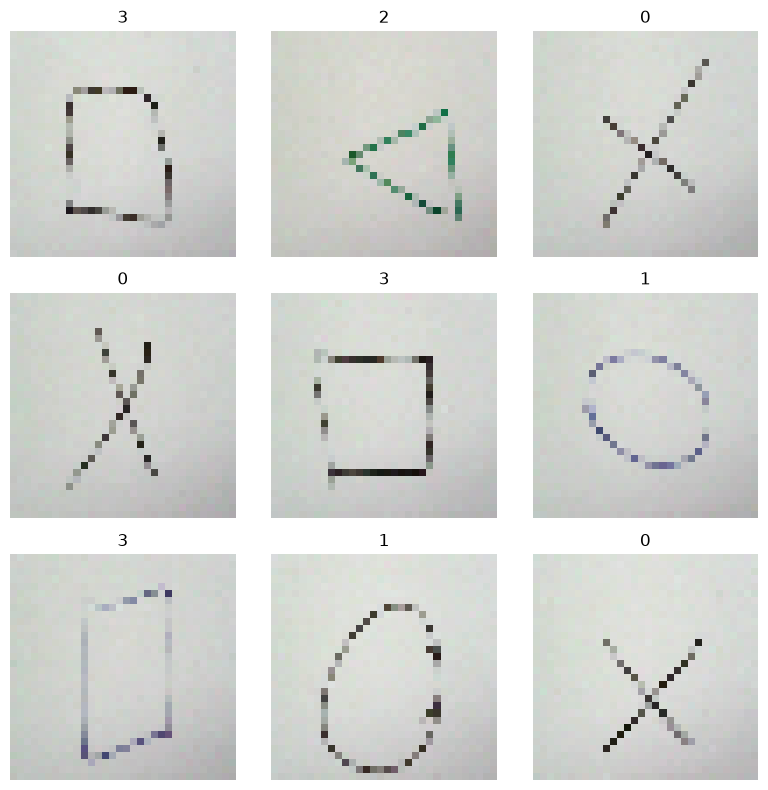

In [7]:
# =============================================================================
# Preview 9 training images
# =============================================================================
plt.figure(figsize=(8, 8))
for images, labels in train_dataset.take(1):
    for i in range( min(BATCH_SIZE, 9)): # choose minimum of batch size and a nuber
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))        
        label_index = labels[i].numpy().argmax()
        plt.title(class_names[label_index])
        plt.axis("off")

plt.tight_layout()

In [8]:
def normalize_images(images, labels):
    return tf.cast(images, tf.float32) / 255.0, labels

train_dataset = train_dataset.map(normalize_images)
validation_dataset = validation_dataset.map(normalize_images)
test_dataset = test_dataset.map(normalize_images)

In [9]:
# =============================================================================
# Prefetch data:
# It prepares the next batch while the model works on the current one, which 
# can improve training speed. It doesn’t split data or change the labels. 
# AUTOTUNE lets TensorFlow choose how much to prefetch, but it may use more 
# RAM. On a memory-constrained Raspberry Pi, try limiting it to one batch:
# =============================================================================
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

print('Number of training batches: %d' % tf.data.experimental.cardinality(train_dataset))
print('Number of validation batches: %d' % tf.data.experimental.cardinality(validation_dataset))
print('Number of test batches: %d' % tf.data.experimental.cardinality(test_dataset))

Number of training batches: 4
Number of validation batches: 1
Number of test batches: 1


In [10]:
# =============================================================================
# Data Augmentation
# =============================================================================
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(factor=0.1),
    layers.RandomZoom(0.05),   
])

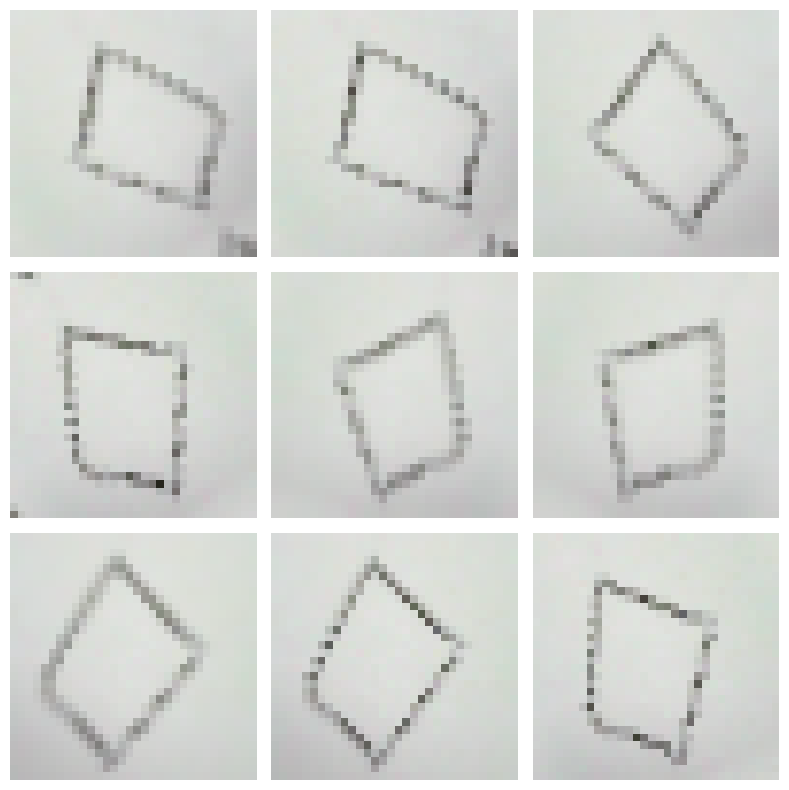

In [11]:
for image, _ in train_dataset.take(1):
  # Display the original image and 9 augmented versions
  plt.figure(figsize=(8, 8))
  first_image = image[0]
  for i in range( min(BATCH_SIZE, 9)):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    display_image = augmented_image[0].numpy()
    if display_image.max() > 1.0:
      display_image = display_image / 255.0
    plt.imshow(np.clip(display_image, 0.0, 1.0))
    plt.axis('off')

plt.tight_layout()

In [ ]:
# =============================================================================
# Create neural network with x layers and (n_1, ..., n_i) neurons per layer.
# =============================================================================
# 1. Model
model = "medium"
if model == "small":
    model = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        # For RGB input, you can optionally convert to grayscale:
        layers.Lambda(tf.image.rgb_to_grayscale),

        # DATA AUGMENTATION
        data_augmentation,
        layers.Flatten(),                              
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.3),        
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3), 
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),                                                                                         
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
elif model == "medium":
    model = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        
        # For RGB input, you can optionally convert to grayscale:
        layers.Lambda(tf.image.rgb_to_grayscale),

        # DATA AUGMENTATION
        data_augmentation,

        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ])

In [13]:
# =============================================================================
# Take a look at our model
# =============================================================================
if debug:
    print(model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        32,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,492 (185.52 KB)

 Trainable params: 47,492 (185.52 KB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
# =============================================================================
# HYPERPARAMETERS
# =============================================================================
LEARNING_RATE = 0.0003 # = 3e-4

lr = "fixed"                                                # HYPERPARAMETER 4
if lr == "fixed":
    learning_rate = LEARNING_RATE 
elif lr == "decay":
    learning_rate = keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=LEARNING_RATE,
        decay_steps=500, # 10% every 10 epochs = ???
        decay_rate=0.9
    )
      
elif lr == "plateu":                                    
    learning_rate = LEARNING_RATE
    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
    )


optimizer = "adam"                                           # HYPERPARAMETER 5
if optimizer == "adam":
    optimizer_fcn = keras.optimizers.Adam(learning_rate=learning_rate)
elif optimizer == "sgd":
    optimizer_fcn = keras.optimizers.SGD(learning_rate=learning_rate)
elif optimizer == "rmsprop":
    optimizer_fcn = keras.optimizers.RMSprop(learning_rate=learning_rate)
elif optimizer == "adagrad":
    optimizer_fcn = keras.optimizers.Adagrad(learning_rate=learning_rate)

loss_fcn = "categorical_crossentropy"       
#loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)                    
#loss = "sparse_categorical_crossentropy"
#loss = "mean_squared_error"
#...

metric_fcn = ["accuracy"]
#metric=["sparse_categorical_accuracy"]
#...

model.compile(
    loss=loss_fcn,
    optimizer=optimizer_fcn,
    metrics=metric_fcn,
)

In [15]:
# =============================================================================
# TensorBoard Logging
# =============================================================================
log_path = "logs/fit"
tensorboard_callback = keras.callbacks.TensorBoard(
    log_dir=log_path,
    histogram_freq=1
)

# Starten in Shell: tensorboard --logdir datasets/symbols/logs/fit

In [16]:
# =============================================================================
# Early stopping after e.g. 10 epochs if loss does not improve
# =============================================================================
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
)

In [17]:
# =============================================================================
# Callback for training
# =============================================================================
from datetime import datetime
from pathlib import Path

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
checkpoint_dir = Path(checkpoint_filepath)
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_file = checkpoint_dir / f"chpt_{timestamp}.keras"

print(checkpoint_file)  # Should end with chpt_YYYYMMDD_HHMMSS.keras

# Set verbose flag to 0 to omit loss/accuracy output per epoch
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_file),
    monitor='val_loss',       # metric to monitor
    save_best_only=True,      # only save when metric improves
    mode='auto',              # minimize loss and aximize accuracy
    verbose=0,                # Print a line when the model is saved
)

/home/pi/ml_project/datasets/symbols/chpt/chpt_20261121_125605.keras


In [18]:
# =============================================================================
# Train the neuronal network for some epochs.
# =============================================================================
history = model.fit(
    train_dataset, 
    validation_data=validation_dataset,
    epochs=EPOCHS, 
    verbose=1, 
    callbacks=[checkpoint, 
               #early_stopping,
               reduce_lr,
               #tensorboard_callback,
               ])

Epoch 1/300


/home/pi/ml_project/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 603ms/step - accuracy: 0.2479 - loss: 1.4137 - val_accuracy: 0.2500 - val_loss: 1.3901
Epoch 2/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 263ms/step - accuracy: 0.2479 - loss: 1.3952 - val_accuracy: 0.2500 - val_loss: 1.3880
Epoch 3/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 185ms/step - accuracy: 0.2562 - loss: 1.3875 - val_accuracy: 0.2500 - val_loss: 1.3828
Epoch 4/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 154ms/step - accuracy: 0.2562 - loss: 1.3847 - val_accuracy: 0.2500 - val_loss: 1.3839
Epoch 5/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 256ms/step - accuracy: 0.2562 - loss: 1.3857 - val_accuracy: 0.2500 - val_loss: 1.3812
Epoch 6/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 203ms/step - accuracy: 0.2645 - loss: 1.3879 - val_accuracy: 0.3333 - val_loss: 1.3814
Epoch 7/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 139ms/step - accuracy: 0.2645 - loss: 1.3835 - val_accuracy: 0.2500 - val_loss: 1.3797
Epoch 8/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 153ms/step - accuracy: 0.2727 - loss: 1.3836 - val_accuracy: 0.2917 - val_loss: 1.3

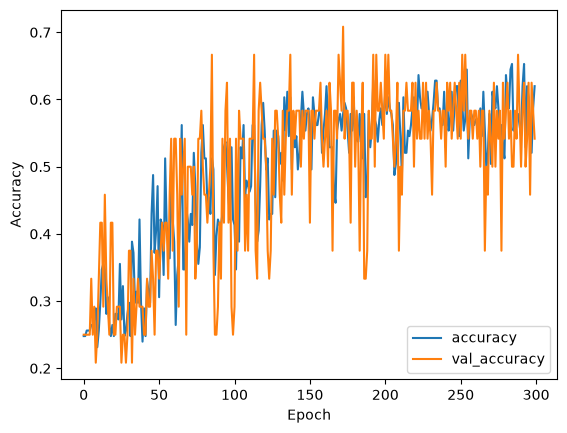

In [19]:
# =============================================================================
# Plot train and val accuracy.
# =============================================================================

plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.show()


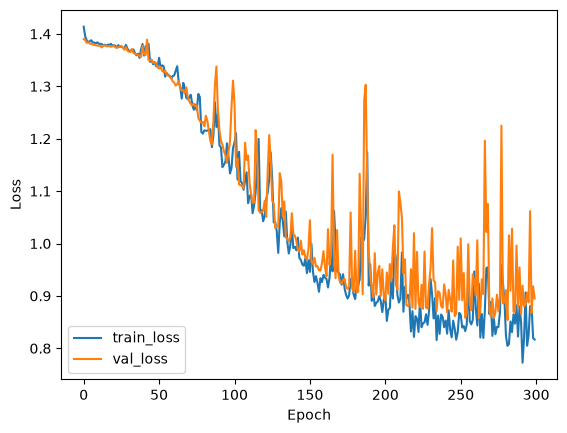

In [20]:
# =============================================================================
# Plot train and val loss.
# =============================================================================

plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='lower left')
plt.show()

In [21]:
# =============================================================================
# Load pretrained dataset weights to e.g. test on new (unseen) data.
# =============================================================================
model.load_weights( str(checkpoint_file) )

In [22]:
# =============================================================================
# Test Accuracy on test set
# =============================================================================
results = model.evaluate(test_dataset, 
                         verbose=1, 
                         return_dict=True,
                         )

loss = results["loss"]
accuracy = results.get("accuracy")  # available if you compiled with an accuracy metric

print("Test loss:", loss)
print("Test accuracy:", accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.5161 - loss: 0.8408
Test loss: 0.8408263325691223
Test accuracy: 0.5161290168762207


E0000 00:00:1795262375.445752   39216 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Shapes of y_true and y_pred: (31,) (31,)
Classes: ['0', '1', '2', '3']


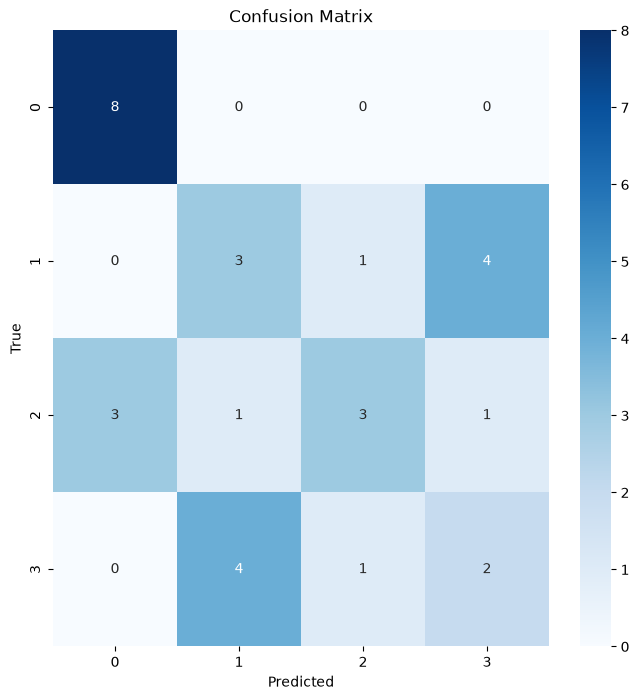


Classification Report:
              precision    recall  f1-score   support

           0       0.73      1.00      0.84         8
           1       0.38      0.38      0.38         8
           2       0.60      0.38      0.46         8
           3       0.29      0.29      0.29         7

    accuracy                           0.52        31
   macro avg       0.50      0.51      0.49        31
weighted avg       0.50      0.52      0.50        31



In [23]:
# =============================================================================
# Confusion matrix and classification report on the test set
# =============================================================================
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
print("Shapes of y_true and y_pred:", y_true.shape, y_pred.shape)
print("Classes:", class_names)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

In [27]:
# =============================================================================
# Testing on a single image.
# =============================================================================
# Example image from the test set; change the class folder or filename as needed.
img_path = Path(dataset_for_training_split) / "test" / "0" / "85.png"

img_pred_bgr = cv2.imread(str(img_path))
if img_pred_bgr is None:
    raise FileNotFoundError(f"Could not read image: {img_path}")

# OpenCV reads BGR; image_dataset_from_directory uses RGB.
img_pred = cv2.cvtColor(img_pred_bgr, cv2.COLOR_BGR2RGB)
img_pred = cv2.resize(img_pred, (IMG_WIDTH, IMG_HEIGHT))
data_pred = np.expand_dims(img_pred.astype(np.float32) / 255.0, axis=0)

result = model.predict(data_pred, verbose=0)

symbol_names = {
    "0": "Cross",
    "1": "Circle",
    "2": "Triangle",
    "3": "Square",
}
print("Probability for classes:")
for class_name, probability in zip(class_names, result[0]):
    print(f"{symbol_names[class_name]}: {probability * 100:.2f}%")

Probability for classes:
Cross: 85.44%
Circle: 0.78%
Triangle: 13.70%
Square: 0.07%


E0000 00:00:1795262530.919098   39216 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


In [28]:
# =============================================================================
# Output class: 
# Translate the predicted class label (0, 1, 2, 3) to its symbol.
# =============================================================================

predicted_index = int(np.argmax(result[0]))
predicted_class = class_names[predicted_index]
predicted_symbol = symbol_names[predicted_class]
print(f"{predicted_symbol} detected! (class {predicted_class})")

Cross detected! (class 0)
